# Markov Model of T2D-to-CVD Transition

Two-state absorbing Markov chain (State 0 = T2D, CVD-free; State 1 = incident CVD) over the same 1-5 year horizons used throughout. Censoring is handled via the standard survival-analysis treatment (life-table / Kaplan-Meier), not as a literal third state.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2, chi2_contingency
import statsmodels.formula.api as smf
from lifelines import KaplanMeierFitter
import warnings
warnings.filterwarnings('ignore')

BASE = '../../'  
HORIZONS = [1, 2, 3, 4, 5]
USYD = ['#E64626', '#DAA8A2', '#71A399', '#8F9EC9', '#1A345E']

df = pd.read_csv(BASE + 'modeling_dataset.csv')
print(f'{len(df):,} patients, {df.incident_cvd.sum():,} incident CVD events ({100*df.incident_cvd.mean():.1f}%)')
print(f'years_followup: min={df.years_followup.min():.2f}, median={df.years_followup.median():.2f}, max={df.years_followup.max():.2f}')

3,050 patients, 472 incident CVD events (15.5%)
years_followup: min=0.00, median=2.89, max=18.54


**State-space diagram**: the two states and the one allowed direction of movement, drawn below for the thesis write-up.

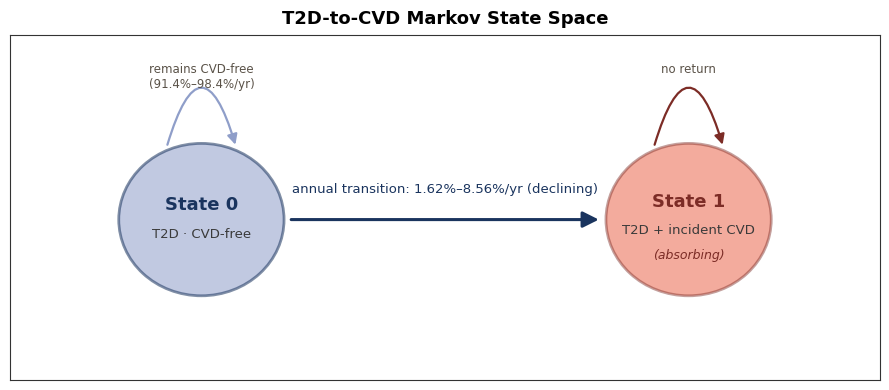

saved markov_state_diagram.png


In [2]:
import matplotlib.patches as mpatches
from matplotlib.patches import Circle, FancyArrowPatch

fig, ax = plt.subplots(figsize=(9, 4))
ax.set_xlim(0, 10)
ax.set_ylim(0, 4.3)
ax.set_xticks([])
ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color('#333333')
    spine.set_linewidth(0.8)

# State 0 -- T2D, CVD-free
s0 = Circle((2.2, 2), 0.95, facecolor=USYD[3], edgecolor=USYD[4], linewidth=2, alpha=0.55, zorder=2)
ax.add_patch(s0)
ax.text(2.2, 2.18, 'State 0', ha='center', va='center', fontsize=13, fontweight='bold', color=USYD[4], zorder=3)
ax.text(2.2, 1.82, 'T2D \u00b7 CVD-free', ha='center', va='center', fontsize=9.5, color='#3a3a3a', zorder=3)

# State 1 -- T2D + incident CVD, absorbing
s1 = Circle((7.8, 2), 0.95, facecolor=USYD[0], edgecolor='#7c2c26', linewidth=2, alpha=0.45, zorder=2)
ax.add_patch(s1)
ax.text(7.8, 2.22, 'State 1', ha='center', va='center', fontsize=13, fontweight='bold', color='#7c2c26', zorder=3)
ax.text(7.8, 1.86, 'T2D + incident CVD', ha='center', va='center', fontsize=9.5, color='#3a3a3a', zorder=3)
ax.text(7.8, 1.55, '(absorbing)', ha='center', va='center', fontsize=9, style='italic', color='#7c2c26', zorder=3)

# transition arrow, State 0 -> State 1
arrow = FancyArrowPatch((3.2, 2), (6.8, 2), arrowstyle='-|>', mutation_scale=24,
                         linewidth=2.2, color=USYD[4], zorder=1)
ax.add_patch(arrow)
ax.text(5.0, 2.3, 'annual transition: 1.62%\u20138.56%/yr (declining)', ha='center', va='bottom',
        fontsize=9.5, color=USYD[4])

# self-loop, State 0 (remains CVD-free)
loop0 = FancyArrowPatch((1.8, 2.9), (2.6, 2.9), connectionstyle='arc3,rad=-1.7',
                         arrowstyle='-|>', mutation_scale=15, linewidth=1.6, color=USYD[3], zorder=1)
ax.add_patch(loop0)
ax.text(2.2, 3.95, 'remains CVD-free\n(91.4%\u201398.4%/yr)', ha='center', va='top', fontsize=8.5, color='#5a5248')

# self-loop, State 1 (no return)
loop1 = FancyArrowPatch((7.4, 2.9), (8.2, 2.9), connectionstyle='arc3,rad=-1.7',
                         arrowstyle='-|>', mutation_scale=15, linewidth=1.6, color='#7c2c26', zorder=1)
ax.add_patch(loop1)
ax.text(7.8, 3.95, 'no return', ha='center', va='top', fontsize=8.5, color='#5a5248')

ax.set_title('T2D-to-CVD Markov State Space', fontsize=13, fontweight='bold', pad=8)
plt.tight_layout()
plt.savefig(BASE + 'thesis/markov/markov_state_diagram.png', dpi=300, bbox_inches='tight')
plt.show()
print('saved markov_state_diagram.png')

## 1. Life-table (discrete-time) transition probability

Annual hazard = transitions / at-risk, per year since diagnosis -- the discrete-time analogue of Kaplan-Meier.

In [3]:
def life_table(sub):
    rows = []
    for k in HORIZONS:
        at_risk = sub[sub['years_followup'] >= (k - 1)]
        n_at_risk = len(at_risk)
        transitioned = at_risk[(at_risk['incident_cvd']) &
                                (at_risk['years_followup'] >= (k - 1)) &
                                (at_risk['years_followup'] < k)]
        n_transition = len(transitioned)
        p_transition = n_transition / n_at_risk if n_at_risk > 0 else np.nan
        rows.append(dict(horizon=f'{k}y', n_at_risk=n_at_risk, n_transition=n_transition,
                          p_state0_to_state1=p_transition, p_remain_state0=1 - p_transition))
    lt = pd.DataFrame(rows)
    # cumulative probability of having transitioned to State 1 by horizon k = 1 - product of survival probs
    lt['cumulative_p_state1'] = 1 - (1 - lt['p_state0_to_state1']).cumprod()
    lt['cumulative_p_state0'] = 1 - lt['cumulative_p_state1']
    return lt

lt_pooled = life_table(df)
print('=== Pooled transition probability matrix, per horizon (life-table estimator) ===')
lt_pooled.round(4)

=== Pooled transition probability matrix, per horizon (life-table estimator) ===


,horizon,n_at_risk,n_transition,p_state0_to_state1,p_remain_state0,cumulative_p_state1,cumulative_p_state0
0,1y,3050,261,0.0856,0.9144,0.0856,0.9144
1,2y,2425,67,0.0276,0.9724,0.1108,0.8892
2,3y,1961,52,0.0265,0.9735,0.1344,0.8656
3,4y,1465,31,0.0212,0.9788,0.1527,0.8473
4,5y,1048,17,0.0162,0.9838,0.1665,0.8335


## 2. Kaplan-Meier cumulative incidence

Continuous-time cross-check: cumulative incidence = 1 - S(t), using exact event times rather than annual grouping.

In [4]:
kmf = KaplanMeierFitter()
kmf.fit(df['years_followup'], df['incident_cvd'].astype(int))

km_at_horizons = pd.Series(
    [1 - kmf.survival_function_at_times(h).iloc[0] for h in HORIZONS],
    index=HORIZONS, name='cumulative_p_state1_km'
)
print('=== Kaplan-Meier-based cumulative incidence of State 1 (CVD), at each horizon ===')
print(km_at_horizons.round(4))

comparison = lt_pooled[['horizon', 'cumulative_p_state1']].copy()
comparison['km_cumulative_p_state1'] = km_at_horizons.values
comparison['abs_diff'] = (comparison['cumulative_p_state1'] - comparison['km_cumulative_p_state1']).abs()
print()
print('=== Life-table vs. Kaplan-Meier, cumulative State-1 probability ===')
comparison.round(4)

=== Kaplan-Meier-based cumulative incidence of State 1 (CVD), at each horizon ===
1    0.0880
2    0.1152
3    0.1414
4    0.1619
5    0.1793
Name: cumulative_p_state1_km, dtype: float64

=== Life-table vs. Kaplan-Meier, cumulative State-1 probability ===


,horizon,cumulative_p_state1,km_cumulative_p_state1,abs_diff
0,1y,0.0856,0.0880,0.0024
1,2y,0.1108,0.1152,0.0044
2,3y,0.1344,0.1414,0.0069
3,4y,0.1527,0.1619,0.0091
4,5y,0.1665,0.1793,0.0128


## 3. Testing the time-homogeneity (Markov) assumption

Chi-square test of homogeneity across the five annual hazards, plus a discrete-time hazard logistic regression (transitioned ~ horizon + age) testing whether horizon predicts transition beyond risk-set membership.

In [5]:
# Test 1: chi-square homogeneity test across the 5 year-specific hazards
obs_transitions = lt_pooled['n_transition'].values
obs_at_risk = lt_pooled['n_at_risk'].values
pooled_hazard = obs_transitions.sum() / obs_at_risk.sum()
expected_transitions = obs_at_risk * pooled_hazard

chi2_stat = np.sum((obs_transitions - expected_transitions) ** 2 / expected_transitions)
df_chi2 = len(HORIZONS) - 1
p_homogeneity = chi2.sf(chi2_stat, df_chi2)

print('=== Test 1: chi-square test of homogeneity across annual hazards ===')
print(f'Pooled (constant) hazard estimate: {pooled_hazard:.4f}')
print(f'chi-square = {chi2_stat:.3f}, df = {df_chi2}, p = {p_homogeneity:.2e}')
print(f'{"REJECT" if p_homogeneity < 0.05 else "FAIL TO REJECT"} time-homogeneity at alpha=0.05')

=== Test 1: chi-square test of homogeneity across annual hazards ===
Pooled (constant) hazard estimate: 0.0430
chi-square = 187.920, df = 4, p = 1.48e-39
REJECT time-homogeneity at alpha=0.05


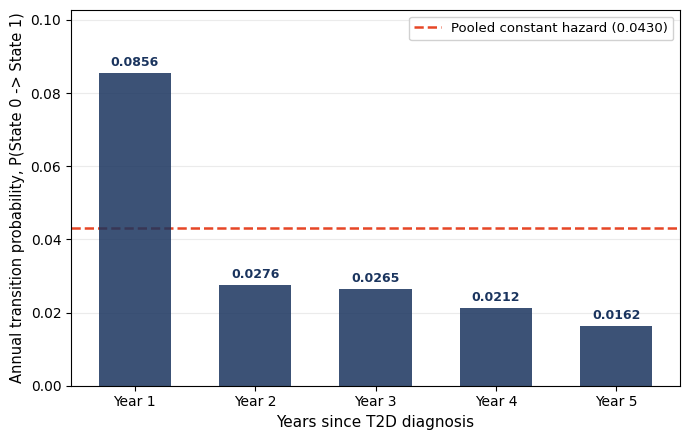

saved markov_annual_hazard_vs_constant.png


In [6]:
fig, ax = plt.subplots(figsize=(7, 4.5))

x = [1, 2, 3, 4, 5]
annual_p = lt_pooled['p_state0_to_state1'].values

bars = ax.bar(x, annual_p, width=0.6, color=USYD[4], alpha=0.85, zorder=2)
for xi, p in zip(x, annual_p):
    ax.annotate(f'{p:.4f}', (xi, p), textcoords='offset points', xytext=(0, 5),
                ha='center', fontsize=9, fontweight='bold', color=USYD[4], zorder=3)

ax.axhline(pooled_hazard, color=USYD[0], linestyle='--', linewidth=1.8,
           label=f'Pooled constant hazard ({pooled_hazard:.4f})', zorder=1)

ax.set_xlabel('Years since T2D diagnosis', fontsize=11)
ax.set_ylabel('Annual transition probability, P(State 0 -> State 1)', fontsize=10.5)
ax.set_xticks(x)
ax.set_xticklabels([f'Year {k}' for k in x])
ax.set_ylim(0, max(annual_p) * 1.2)
ax.legend(fontsize=9.5, loc='upper right', framealpha=0.9)
ax.grid(alpha=0.25, axis='y')
plt.tight_layout()
plt.savefig(BASE + 'thesis/markov/markov_annual_hazard_vs_constant.png', dpi=300, bbox_inches='tight')
plt.show()
print('saved markov_annual_hazard_vs_constant.png')

In [ ]:
risk_set_rows = []
for k in HORIZONS:
    at_risk = df[df['years_followup'] >= (k - 1)].copy()
    at_risk['transitioned'] = ((at_risk['incident_cvd']) &
                                (at_risk['years_followup'] >= (k - 1)) &
                                (at_risk['years_followup'] < k)).astype(int)
    at_risk['horizon'] = k
    risk_set_rows.append(at_risk[['person_id', 'age', 'sex', 'horizon', 'transitioned']])

risk_set_df = pd.concat(risk_set_rows, ignore_index=True)

model = smf.logit('transitioned ~ horizon + age', data=risk_set_df).fit(disp=0)
print('=== Test 2: discrete-time hazard logistic regression ===')
print(model.summary().tables[1])
print()
horizon_p = model.pvalues['horizon']
print(f"horizon coefficient p-value = {horizon_p:.2e} -- "
      f"{'significant' if horizon_p < 0.05 else 'not significant'} "
      f"at alpha=0.05: time-since-diagnosis {'DOES' if horizon_p < 0.05 else 'does NOT'} predict transition "
      f"probability beyond risk-set membership.")

=== Test 2: discrete-time hazard logistic regression ===
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -5.1748      0.293    -17.684      0.000      -5.748      -4.601
horizon       -0.5300      0.048    -11.020      0.000      -0.624      -0.436
age            0.0478      0.004     12.085      0.000       0.040       0.056

horizon coefficient p-value = 3.07e-28 -- significant at alpha=0.05: time-since-diagnosis DOES predict transition probability beyond risk-set membership.


## 4. Sex-stratified transition probabilities

Same life-table estimator, computed separately for male and female patients.

In [8]:
lt_male = life_table(df[df['sex'] == 'M'])
lt_female = life_table(df[df['sex'] == 'F'])

sex_comparison = pd.DataFrame({
    'horizon': lt_male['horizon'],
    'male_annual_p_transition': lt_male['p_state0_to_state1'].values,
    'female_annual_p_transition': lt_female['p_state0_to_state1'].values,
    'male_cumulative_p_state1': lt_male['cumulative_p_state1'].values,
    'female_cumulative_p_state1': lt_female['cumulative_p_state1'].values,
})
sex_comparison['cumulative_gap_F_minus_M'] = (
    sex_comparison['female_cumulative_p_state1'] - sex_comparison['male_cumulative_p_state1']
)
print('=== Sex-stratified transition probabilities ===')
sex_comparison.round(4)

=== Sex-stratified transition probabilities ===


,horizon,male_annual_p_transition,female_annual_p_transition,male_cumulative_p_state1,female_cumulative_p_state1,cumulative_gap_F_minus_M
0,1y,0.0906,0.0793,0.0906,0.0793,-0.0113
1,2y,0.0289,0.0260,0.1169,0.1032,-0.0137
2,3y,0.0315,0.0200,0.1447,0.1212,-0.0235
3,4y,0.0219,0.0202,0.1634,0.1389,-0.0245
4,5y,0.0202,0.0110,0.1803,0.1484,-0.0319


In [9]:
# Formal test: does sex predict transition probability, controlling for horizon and age?
model_sex = smf.logit('transitioned ~ horizon + age + C(sex)', data=risk_set_df).fit(disp=0)
print('=== Does sex independently predict transition probability (controlling for horizon, age)? ===')
print(model_sex.summary().tables[1])
sex_p = model_sex.pvalues[[c for c in model_sex.pvalues.index if 'sex' in c.lower()][0]]
print()
print(f'Sex coefficient p-value = {sex_p:.2e}')

=== Does sex independently predict transition probability (controlling for horizon, age)? ===
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept      -5.2229      0.298    -17.548      0.000      -5.806      -4.640
C(sex)[T.M]     0.1011      0.103      0.983      0.326      -0.101       0.303
horizon        -0.5306      0.048    -11.029      0.000      -0.625      -0.436
age             0.0477      0.004     12.007      0.000       0.040       0.055

Sex coefficient p-value = 3.26e-01


## 5. Validation against raw empirical proportions

Compares the life-table cumulative probability against the crude event rate among eligible patients at each horizon.

In [10]:
empirical_rows = []
for k in HORIZONS:
    elig_col, label_col = f'eligible_{k}y', f'label_{k}y'
    n_elig = int(df[elig_col].sum())
    n_event = int((df[label_col] == 1).sum())
    empirical_rows.append(dict(horizon=f'{k}y', n_eligible=n_elig, n_events=n_event,
                                empirical_p_event=n_event / n_elig))
empirical_df = pd.DataFrame(empirical_rows)

validation = lt_pooled[['horizon', 'cumulative_p_state1']].merge(empirical_df, on='horizon')
validation['kaplan_meier'] = km_at_horizons.values
validation['diff_lifetable_vs_empirical'] = validation['cumulative_p_state1'] - validation['empirical_p_event']
print('=== Model-implied vs. empirical cumulative CVD probability ===')
validation.round(4)

=== Model-implied vs. empirical cumulative CVD probability ===


,horizon,cumulative_p_state1,n_eligible,n_events,empirical_p_event,kaplan_meier,diff_lifetable_vs_empirical
0,1y,0.0856,2686,261,0.0972,0.0880,-0.0116
1,2y,0.1108,2289,328,0.1433,0.1152,-0.0325
2,3y,0.1344,1845,380,0.2060,0.1414,-0.0715
3,4y,0.1527,1459,411,0.2817,0.1619,-0.1290
4,5y,0.1665,956,428,0.4477,0.1793,-0.2812


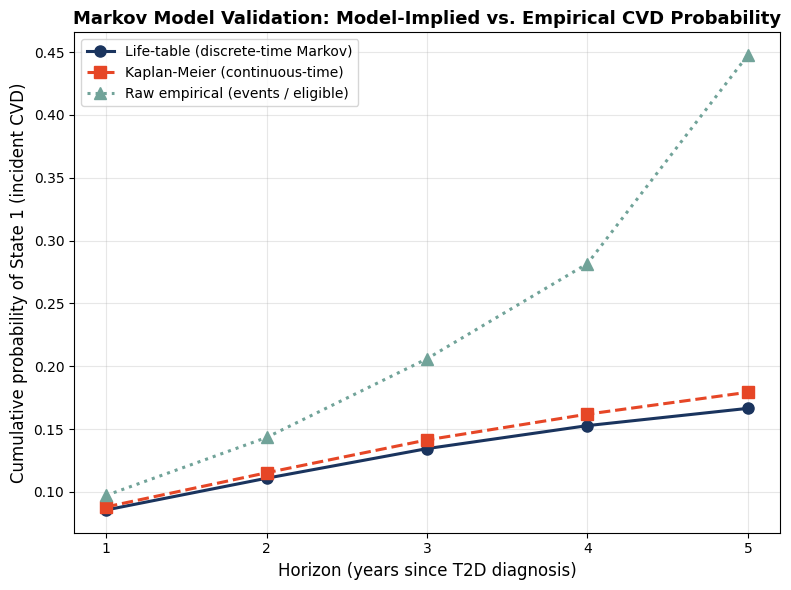

saved markov_validation_plot.png


In [11]:
fig, ax = plt.subplots(figsize=(8, 6))
x = [int(h[:-1]) for h in validation['horizon']]

ax.plot(x, validation['cumulative_p_state1'], 'o-', color=USYD[4], linewidth=2.2, markersize=8,
        label='Life-table (discrete-time Markov)')
ax.plot(x, validation['kaplan_meier'], 's--', color=USYD[0], linewidth=2.2, markersize=8,
        label='Kaplan-Meier (continuous-time)')
ax.plot(x, validation['empirical_p_event'], '^:', color=USYD[2], linewidth=2.2, markersize=8,
        label='Raw empirical (events / eligible)')

ax.set_xlabel('Horizon (years since T2D diagnosis)', fontsize=12)
ax.set_ylabel('Cumulative probability of State 1 (incident CVD)', fontsize=12)
ax.set_title('Markov Model Validation: Model-Implied vs. Empirical CVD Probability', fontsize=13, fontweight='bold')
ax.set_xticks(x)
ax.legend(fontsize=10)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(BASE + 'thesis/markov/markov_validation_plot.png', dpi=300, bbox_inches='tight')
plt.show()
print('saved markov_validation_plot.png')

## 6. Progression figures: pooled and sex-stratified

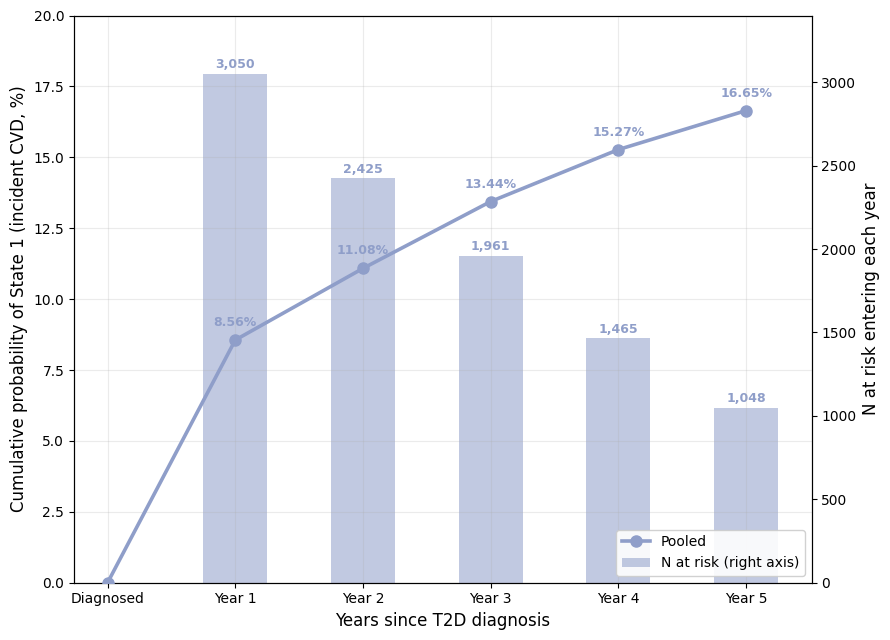

saved markov_progression_plot_pooled.png


In [14]:
fig, ax1 = plt.subplots(figsize=(9, 6.5))
ax2 = ax1.twinx()

x_bar = [1, 2, 3, 4, 5]
n_at_risk = lt_pooled['n_at_risk'].values
ax2.bar(x_bar, n_at_risk, width=0.5, color=USYD[3], alpha=0.55, label='N at risk (right axis)', zorder=1)
for xi, ni in zip(x_bar, n_at_risk):
    ax2.annotate(f'{ni:,}', (xi, ni), textcoords='offset points', xytext=(0, 4),
                 ha='center', fontsize=9, color=USYD[3], fontweight='bold', zorder=2)

x_line = [0, 1, 2, 3, 4, 5]
pooled_cum = [0] + list(lt_pooled['cumulative_p_state1'].values * 100)

ax1.plot(x_line, pooled_cum, 'o-', color=USYD[3], linewidth=2.6, markersize=8, label='Pooled', zorder=3)

for xi, yi in zip(x_line[1:], pooled_cum[1:]):
    ax1.annotate(f'{yi:.2f}%', (xi, yi), textcoords='offset points', xytext=(0, 10),
                 ha='center', fontsize=9, fontweight='bold', color=USYD[3])

ax1.set_xlabel('Years since T2D diagnosis', fontsize=12)
ax1.set_ylabel('Cumulative probability of State 1 (incident CVD, %)', fontsize=12)
ax2.set_ylabel('N at risk entering each year', fontsize=12)
ax1.set_xticks(x_line)
ax1.set_xticklabels(['Diagnosed', 'Year 1', 'Year 2', 'Year 3', 'Year 4', 'Year 5'])
ax1.set_ylim(0, 20)
ax2.set_ylim(0, 3400)
ax1.set_zorder(ax2.get_zorder() + 1)
ax1.patch.set_visible(False)

lines1, labels1 = ax1.get_legend_handles_labels()
bars2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + bars2, labels1 + labels2, loc='lower right', fontsize=10, framealpha=0.9)
ax1.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(BASE + 'thesis/markov/markov_progression_plot_pooled.png', dpi=300, bbox_inches='tight')
plt.show()
print('saved markov_progression_plot_pooled.png')

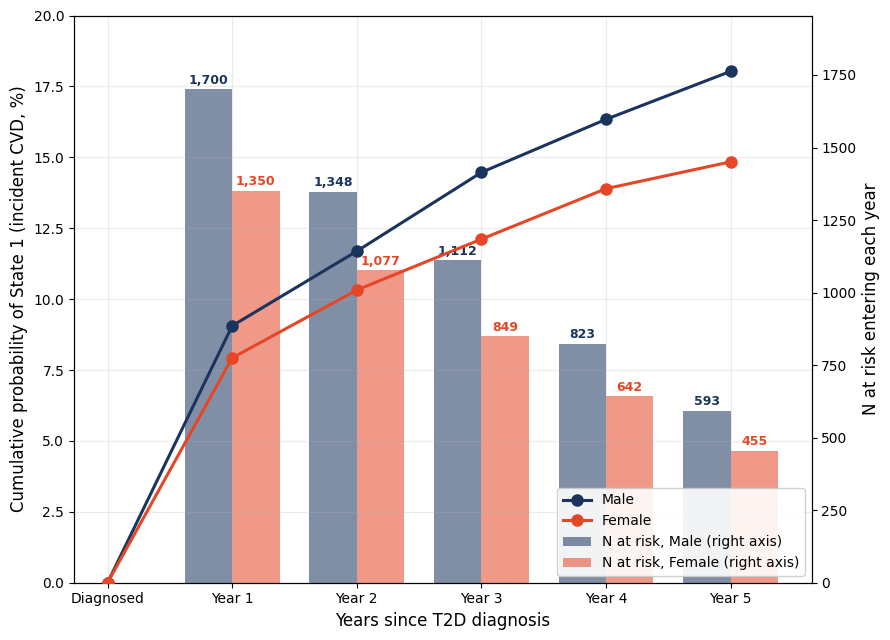

saved markov_progression_plot_sex_stratified.png


In [15]:
fig, ax1 = plt.subplots(figsize=(9, 6.5))
ax2 = ax1.twinx()

x_bar = np.array([1, 2, 3, 4, 5])
male_n_at_risk = lt_male['n_at_risk'].values
female_n_at_risk = lt_female['n_at_risk'].values
bar_w = 0.38

ax2.bar(x_bar - bar_w / 2, male_n_at_risk, width=bar_w, color=USYD[4], alpha=0.55,
        label='N at risk, Male (right axis)', zorder=1)
ax2.bar(x_bar + bar_w / 2, female_n_at_risk, width=bar_w, color=USYD[0], alpha=0.55,
        label='N at risk, Female (right axis)', zorder=1)
for xi, ni in zip(x_bar, male_n_at_risk):
    ax2.annotate(f'{ni:,}', (xi - bar_w / 2, ni), textcoords='offset points', xytext=(0, 4),
                 ha='center', fontsize=9, color=USYD[4], fontweight='bold', zorder=2)
for xi, ni in zip(x_bar, female_n_at_risk):
    ax2.annotate(f'{ni:,}', (xi + bar_w / 2, ni), textcoords='offset points', xytext=(0, 4),
                 ha='center', fontsize=9, color=USYD[0], fontweight='bold', zorder=2)

x_line = [0, 1, 2, 3, 4, 5]
male_cum = [0] + list(sex_comparison['male_cumulative_p_state1'].values * 100)
female_cum = [0] + list(sex_comparison['female_cumulative_p_state1'].values * 100)

ax1.plot(x_line, male_cum, 'o-', color=USYD[4], linewidth=2.2, markersize=8, label='Male', zorder=3)
ax1.plot(x_line, female_cum, 'o-', color=USYD[0], linewidth=2.2, markersize=8, label='Female', zorder=3)

ax1.set_xlabel('Years since T2D diagnosis', fontsize=12)
ax1.set_ylabel('Cumulative probability of State 1 (incident CVD, %)', fontsize=12)
ax2.set_ylabel('N at risk entering each year', fontsize=12)
ax1.set_xticks(x_line)
ax1.set_xticklabels(['Diagnosed', 'Year 1', 'Year 2', 'Year 3', 'Year 4', 'Year 5'])
ax1.set_ylim(0, 20)
ax2.set_ylim(0, 1.15 * max(male_n_at_risk.max(), female_n_at_risk.max()))
ax1.set_zorder(ax2.get_zorder() + 1)
ax1.patch.set_visible(False)

lines1, labels1 = ax1.get_legend_handles_labels()
bars2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + bars2, labels1 + labels2, loc='lower right', fontsize=10, framealpha=0.9)
ax1.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(BASE + 'thesis/markov/markov_progression_plot_sex_stratified.png', dpi=300, bbox_inches='tight')
plt.show()
print('saved markov_progression_plot_sex_stratified.png')

In [16]:
lt_pooled.to_csv(BASE + 'thesis/markov/markov_transition_matrix_pooled.csv', index=False)
sex_comparison.to_csv(BASE + 'thesis/markov/markov_transition_matrix_sex_stratified.csv', index=False)
validation.to_csv(BASE + 'thesis/markov/markov_validation.csv', index=False)

homogeneity_results = pd.DataFrame([
    dict(test='Chi-square homogeneity (annual hazards)', statistic=chi2_stat, df=df_chi2, p_value=p_homogeneity),
    dict(test='Logistic hazard regression: horizon coefficient', statistic=model.params['horizon'],
         df=np.nan, p_value=horizon_p),
    dict(test='Logistic hazard regression: sex coefficient (controlling horizon, age)',
         statistic=model_sex.params[[c for c in model_sex.params.index if 'sex' in c.lower()][0]],
         df=np.nan, p_value=sex_p),
])
homogeneity_results.to_csv(BASE + 'thesis/markov/markov_homogeneity_test.csv', index=False)

print('All outputs saved to thesis/markov/')
homogeneity_results

All outputs saved to thesis/markov/


,test,statistic,df,p_value
0,Chi-square homogeneity (annual hazards),187.920100,4.0,1.483234e-39
1,Logistic hazard regression: horizon coefficient,-0.529963,NaN,3.074693e-28
2,Logistic hazard regression: sex coefficient (c...,0.101090,NaN,3.257810e-01
